In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("creditcard.csv")
X = df.drop("Class", axis=1)
y = df["Class"]

In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

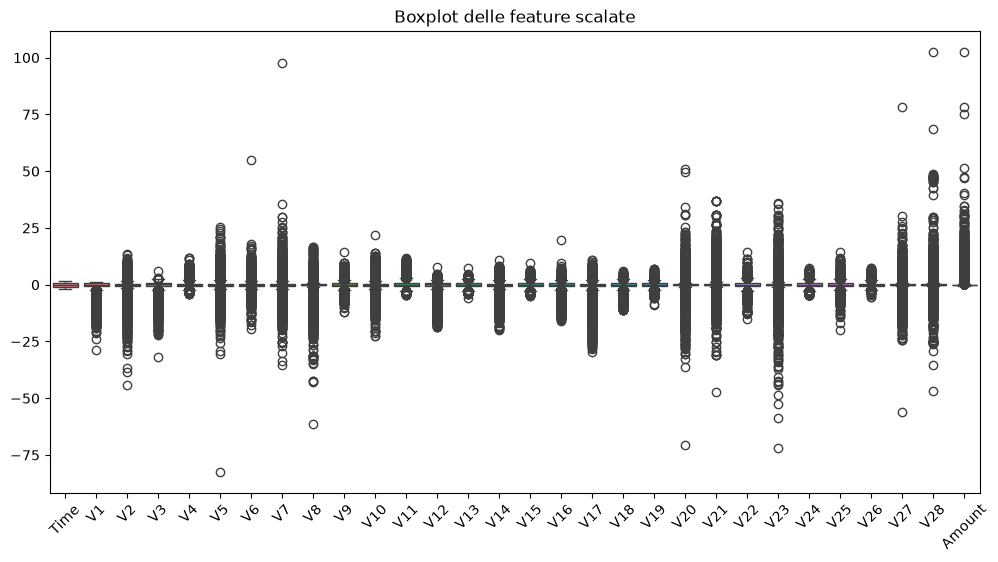

In [50]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled)
plt.xticks(rotation=45)
plt.title("Boxplot delle feature scalate")
plt.show()

In [63]:
m = df['V7'].mean()
s = df['V7'].std()
zscore = (df['V7'] - m) / s

outliers_z = df[zscore.abs() > 3]
print(outliers_z)
print(len(outliers_z))

            Time         V1         V2         V3        V4         V5  \
51          36.0  -1.004929  -0.985978  -0.038039  3.710061  -6.631951   
164        103.0  -6.093248 -12.114213  -5.694973  3.294389  -1.413792   
362        266.0  -2.564961   2.470985   2.649417 -1.564256   1.794297   
370        270.0  -1.356935   0.033724   1.874195 -1.469102  -3.125909   
601        454.0  -3.133891   2.887394   2.178690 -1.576535   1.434510   
...          ...        ...        ...        ...       ...        ...   
284089  172142.0  -1.684733  -0.706470  -2.016701 -0.415001   1.577699   
284106  172159.0  -4.261670  -6.068971   1.887490  0.344141   3.637986   
284154  172199.0  -1.448606  -2.673922  -3.563343 -0.194096   0.007561   
284249  172273.0  -9.030538 -11.112584 -16.233798  3.592021 -40.427726   
284802  172786.0 -11.881118  10.071785  -9.834783 -2.066656  -5.364473   

               V6         V7        V8        V9  ...       V21       V22  \
51       5.122103   4.371691 -2.00

In [64]:
Q1 = df['V7'].quantile(0.25)
Q3 = df['V7'].quantile(0.75)
IQR = Q3 - Q1

limite_inferiore = Q1 - 1.5 * IQR
limite_superiore = Q3 + 1.5 * IQR

print(Q1, Q3, IQR)
print(limite_inferiore, limite_superiore)

-0.5540758790365226 0.5704360728775986 1.1245119519141211
-2.240843806907704 2.2572040007487804


In [65]:
outliers_iqr = df[(df['V5'] < limite_inferiore) | (df['V5'] > limite_superiore)]
print(outliers_iqr)
print(len(outliers_iqr))

            Time         V1         V2        V3        V4        V5  \
8            7.0  -0.894286   0.286157 -0.113192 -0.271526  2.669599   
11          10.0   0.384978   0.616109 -0.874300 -0.094019  2.924584   
18          14.0  -5.401258  -5.450148  1.186305  1.736239  3.049106   
24          22.0  -1.946525  -0.044901 -0.405570 -1.013057  2.941968   
51          36.0  -1.004929  -0.985978 -0.038039  3.710061 -6.631951   
...          ...        ...        ...       ...       ...       ...   
284785  172768.0   0.032887   0.545338 -1.185844 -1.729828  2.932315   
284787  172769.0  -1.029719  -1.110670 -0.636179 -0.840816  2.424360   
284795  172778.0 -12.516732  10.187818 -8.476671 -2.510473 -4.586669   
284802  172786.0 -11.881118  10.071785 -9.834783 -2.066656 -5.364473   
284804  172788.0   1.919565  -0.301254 -3.249640 -0.557828  2.630515   

              V6        V7        V8        V9  ...       V21       V22  \
8       3.721818  0.370145  0.851084 -0.392048  ... -0.07342